# Libraries

In [1]:
import pandas as pd
import numpy as np

#Data visualization
import seaborn as sns
import matplotlib.pyplot as plt

# Data science
from scipy.stats import chisquare
from statsmodels.stats.proportion import proportions_ztest
from statsmodels.stats.multitest import multipletests
from scipy.stats import permutation_test

# Dataset

In [2]:
df = pd.read_csv("raw_data/cookie_cats.csv")

# Data Cleaning

No data quality issues, data are already clean:
* no null values
* no duplicated values

In [48]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 90189 entries, 0 to 90188
Data columns (total 5 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   userid          90189 non-null  int64
 1   version         90189 non-null  str  
 2   sum_gamerounds  90189 non-null  int64
 3   retention_1     90189 non-null  bool 
 4   retention_7     90189 non-null  bool 
dtypes: bool(2), int64(2), str(1)
memory usage: 2.2 MB


In [49]:
df["userid"].duplicated().sum()

np.int64(0)

# Preliminary assessment of the experiment

Steps:
* Check for outliers in number of games
* Check if A/B groups are balanced
* Numerosity of groups is enough to detect the observed difference

## Outliers

Likely issues with outliers

In [50]:
df.describe()

,userid,sum_gamerounds
count,9.018900e+04,90189.000000
mean,4.998412e+06,51.872457
std,2.883286e+06,195.050858
min,1.160000e+02,0.000000
25%,2.512230e+06,5.000000
50%,4.995815e+06,16.000000
75%,7.496452e+06,51.000000
max,9.999861e+06,49854.000000


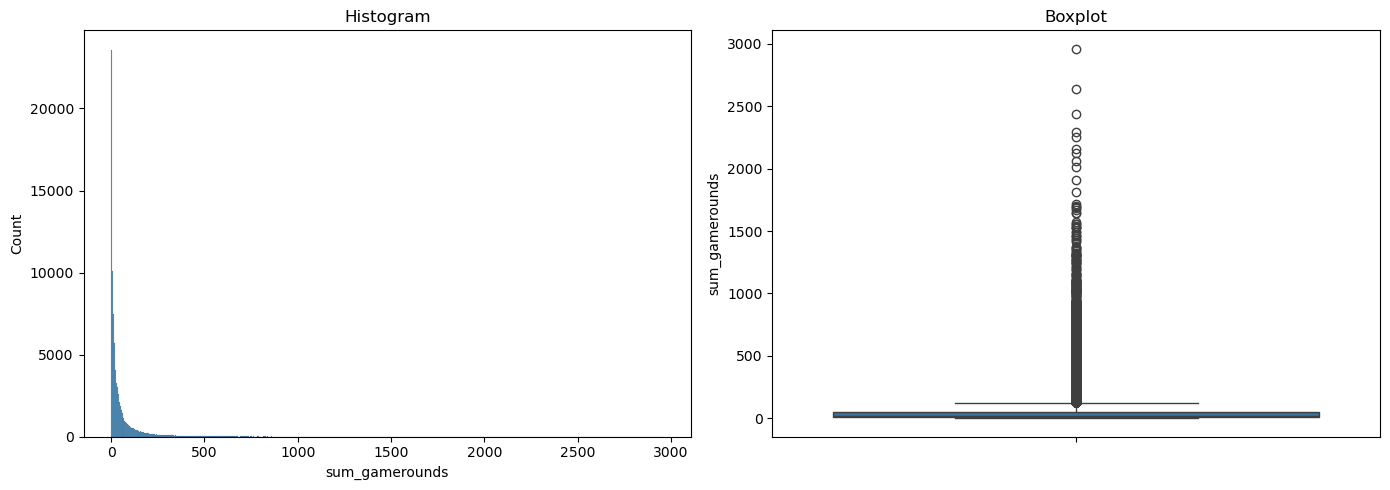

In [51]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

plot_data = df.loc[(df["sum_gamerounds"] < 10000) &
                   (df["sum_gamerounds"] > 0), 
                   "sum_gamerounds"]

sns.histplot(data=plot_data, ax=ax1)
ax1.set_title("Histogram")

sns.boxplot(data=plot_data, ax=ax2)
ax2.set_title("Boxplot")

plt.tight_layout()
plt.show()

There is an user with 50k gamerounds, and there are 4k users with no gamerounds

In [52]:
print("Inactive users =", df.loc[df["sum_gamerounds"] == 0, "userid"].count())
print("Users with many gamerounds")
display(df.loc[df["sum_gamerounds"] > 10000])

Inactive users = 3994
Users with many gamerounds


,userid,version,sum_gamerounds,retention_1,retention_7
57702,6390605,gate_30,49854,False,True


## Co-variate pre-treatment balancing

Co-variate pre-treatment variables (that need to be checked) are:
* number of users
* number of inactive users

Outcome variables are:
* retention_1
* retention_7

### Sample Ratio Mismatch (SRM)

Populations of AB groups seem to be balanced

In [53]:
print("The population is split in half between groups")
df.groupby("version")["userid"].count()

The population is split in half between groups


version
gate_30    44700
gate_40    45489
Name: userid, dtype: int64

Quantitative balance: number of users is coherent with the chosen allocation ratio.\
The chosen allocation ratio is 0.5 (50%)

In [54]:
tot_users = df["userid"].count()
df_grouped = df.groupby("version")["userid"].count()
pct_groups = round(
    (df_grouped/tot_users) * 100,
    1
    )
pct_groups

version
gate_30    49.6
gate_40    50.4
Name: userid, dtype: float64

In [55]:
observed = df_grouped.to_numpy()
expected_ratio = np.array([0.5, 0.5])
expected = tot_users * expected_ratio

print("Observed: ", observed) 
print("Expected: ", expected)

Observed:  [44700 45489]
Expected:  [45094.5 45094.5]


Chi-squared test.\
The significance level is kept 1% instead of the more common 5%, because we are trying to detect issues with the architecture of the experiment:
* `false positive` (experiment not considered suitable when it is) can imply additional investigations, 
* `false negative` (experiment considered suitable when it is not) could make as try to interpret an experiment compromised from the beginning

In [56]:
chi2_stat, p_value = chisquare(
    f_obs=observed,
    f_exp=expected
)

print(f"Chi-square statistic: {chi2_stat:.4f}")
print(f"P-value: {p_value:.4f}")

alpha = 0.01
print("Significance level of", alpha)

if p_value < alpha:
    print("WARNING: Sample Ratio Mismatch detected!")
else:
    print("OK: No significant Sample Ratio Mismatch detected.")

Chi-square statistic: 6.9024
P-value: 0.0086
Significance level of 0.01


The difference between groups is statistically significant, with $alpha = 1$%.\
However, the practical difference between populations is < 1%, so the next step will be carried out 

In [57]:
print(f"Users A: {observed[0]}")
print(f"Users B: {observed[1]}")

print(f"Percentage A: {observed[0]/tot_users:.4%}")
print(f"Percentage B: {observed[1]/tot_users:.4%}")

print(f"Absolute difference: {abs(observed[0]-expected[0]):.0f}")

print(f"Relative difference A: {(observed[0]/expected[0]-1):.2%}")

Users A: 44700
Users B: 45489
Percentage A: 49.5626%
Percentage B: 50.4374%
Absolute difference: 394
Relative difference A: -0.87%


### Standardized Mean Difference (SMD)

Qualitative balance: 2 groups have similar features

First variable: number of games.\
**I'm aware** that there is the anomalous player with 50k games in group A

In [59]:
group_A = df[df["version"] == "gate_30"]["sum_gamerounds"]
group_B = df[df["version"] == "gate_40"]["sum_gamerounds"]

mean_A = group_A.mean()
mean_B = group_B.mean()

std_A = group_A.std()
std_B = group_B.std()

pooled_std = np.sqrt(
    (std_A**2 + std_B**2) / 2
)

smd = (mean_A - mean_B) / pooled_std

print(f"SMD: {smd:.4f}")
print(f"Absolute SMD: {abs(smd):.4f}")

if abs(smd) < 0.05:
    print("Excellent balance")
elif abs(smd) < 0.10:
    print("Acceptable balance")
elif abs(smd) < 0.20:
    print("Potential imbalance")
else:
    print("Relevant imbalance")

SMD: 0.0059
Absolute SMD: 0.0059
Excellent balance


To reduce the effect of extreme values, a logarithmic transformation could be applied to the data.

In [60]:
group_A_log = np.log1p(group_A)
group_B_log = np.log1p(group_B)

mean_A_log = group_A_log.mean()
mean_B_log = group_B_log.mean()

std_A_log = group_A_log.std()
std_B_log = group_B_log.std()

pooled_std_log = np.sqrt(
    (std_A_log**2 + std_B_log**2) / 2
)

smd_log = (mean_A_log - mean_B_log) / pooled_std_log

print(f"SMD: {smd_log:.4f}")
print(f"Absolute SMD: {abs(smd_log):.4f}")

if abs(smd_log) < 0.05:
    print("Excellent balance")
elif abs(smd_log) < 0.10:
    print("Acceptable balance")
elif abs(smd_log) < 0.20:
    print("Potential imbalance")
else:
    print("Relevant imbalance")

SMD: 0.0121
Absolute SMD: 0.0121
Excellent balance


Second variable: number of inactive users

In [61]:
group_A_zero = (group_A == 0).astype(int)
group_B_zero = (group_B == 0).astype(int)

mean_A_zero = group_A_zero.mean()
mean_B_zero = group_B_zero.mean()

std_A_zero = group_A_zero.std()
std_B_zero = group_B_zero.std()

pooled_std_zero = np.sqrt(
    (std_A_zero**2 + std_B_zero**2) / 2
)

smd_zero = (mean_A_zero - mean_B_zero) / pooled_std_zero

print(f"SMD: {smd_zero:.4f}")
print(f"Absolute SMD: {abs(smd_zero):.4f}")

if abs(smd_zero) < 0.05:
    print("Excellent balance")
elif abs(smd_zero) < 0.10:
    print("Acceptable balance")
elif abs(smd_zero) < 0.20:
    print("Potential imbalance")
else:
    print("Relevant imbalance")

SMD: -0.0092
Absolute SMD: 0.0092
Excellent balance


## Numerosity of the groups

Another important assessment in A/B testing is Minimum Detectable Effect (MDE).

In [3]:
# Transpose the grouped DataFrame
df_mde = df.groupby("version").agg(
    users=("userid", "nunique"),
    retention_1=("retention_1", "mean"),
    retention_7=("retention_7", "mean")
).reset_index().transpose()

# Use first row as header and remove it
df_mde.columns = df_mde.iloc[0]
df_mde = df_mde.iloc[1:]
df_mde = df_mde.rename_axis("Parameter").reset_index()
df_mde.columns.name = None

df_mde["abs_diff"] = abs(df_mde["gate_40"] - df_mde["gate_30"])
df_mde["rel_diff"] = df_mde["abs_diff"] / df_mde["gate_30"]

df_mde

,Parameter,gate_30,gate_40,abs_diff,rel_diff
0,users,44700,45489,789,0.017651
1,retention_1,0.448188,0.442283,0.005905,0.013176
2,retention_7,0.190201,0.182,0.008201,0.043119


With the baseline retention of gate_30 (original version of the game):
* 45k users are not enough to detect the variation in retention_1
* 45k users are enough to detect the variation in retention_7

This means that, in these conditions:
* for retention 7 = the MDE will be detected at least 80% of the time, and 5% chance of committing Type I error (false positive)
* for retention 1 = the MDE will be detected less than 80% of the time, with higher chance of committing Type I error (false positive)

# Statistical testing

The purpose is to verify if one version is better than the other (two-sided)

## Test 1: Are the proportions different? 

Z-test for comparison between 2 independent proportions.\
$H_0 : p_A = p_B$ \
$H_1 : p_A \neq p_B$

In [18]:
retention = df.groupby("version").agg(
    users=("userid", "nunique"),
    retention_1=("retention_1", "mean"),
    retention_7=("retention_7", "mean")
)

However, retention 1 day is correlated to retention 7 (if an user quits after 1 day, it cannot still be active after 7 days).\
The probability of a false positive in two tests is increased (it is not 5%, but close to 9.75%).\
$P_{FP} = 1 - (1- 0.05)^2 = 9.75$%, but since the two variables are correlated the value can differ \
 As a consequence, 3 approaches can be adopted:
* Bonferroni correction -> divide $\alpha$ by the number of tests. 
    * This means that instead of 5%, each test should have a $\alpha$ = 2.5%
    * Simple but conservative  
* Holm-Bonferroni -> sort p-values in ascending order, compare the first with 2.5% and the second with 5%
    * more effective in controlling the Family-Wise Error Rate

In [19]:
metrics = ["retention_1", "retention_7"]

results = []

for metric in metrics:

    successes = df.groupby("version")[metric].sum()
    totals = df.groupby("version")[metric].count()

    count = [successes["gate_30"], successes["gate_40"]]
    nobs = [totals["gate_30"], totals["gate_40"]]

    z_stat, p_value = proportions_ztest(
        count=count,
        nobs=nobs,
        alternative="two-sided"
    )

    results.append({
        "metric": metric,
        "z_stat": z_stat,
        "p_value": p_value
    })

results_df = pd.DataFrame(results)

# Holm-Bonferroni
reject, p_adjusted, _, _ = multipletests(
    results_df["p_value"],
    alpha=0.05,
    method="holm"
)

results_df["p_adjusted"] = p_adjusted
results_df["significant"] = reject

display(results_df)

,metric,z_stat,p_value,p_adjusted,significant
0,retention_1,1.784086,0.074410,0.074410,False
1,retention_7,3.164359,0.001554,0.003108,True


So:
* retention 1 = not enough evidence to conclude that groups are statistically different
* retention 7 =  evidence that groups are statistically different

## Test 2: Robustness check

Permutation test:
* All users are pooled, then assigned randomly to a group
* The difference between the 2 groups is calculated
* This process is repeated many times
* The observed difference between the original data is compared with the distribution of the differences
* *p-value* is the probability of obtaining the observed difference, after permutation 

Explorative analysis with 1k permutations

In [31]:
metrics = ["retention_1", "retention_7"]

results = []

for metric in metrics:

    x = df.loc[df["version"] == "gate_30"][metric]
    y = df.loc[df["version"] == "gate_40"][metric]

    res = permutation_test(
        (x, y),
        lambda a, b: np.mean(a) - np.mean(b),
        n_resamples=1_000,
        alternative='two-sided'
    )

    results.append({
        "Metric": metric,
        "Mean gate_30": np.mean(x),
        "Mean gate_40": np.mean(y),
        "Difference": np.mean(x) - np.mean(y),
        "p-value": res.pvalue
    })

results_df = pd.DataFrame(results)

# Holm-Bonferroni correction
reject, p_adjusted, _, _ = multipletests(
    results_df["p-value"],
    alpha=0.05,
    method='holm'
)

results_df["Adjusted p-value (Holm)"] = p_adjusted
results_df["Significant"] = reject

# Formatting
results_df = results_df.round(5)

display(results_df)

,Metric,Mean gate_30,Mean gate_40,Difference,p-value,Adjusted p-value (Holm),Significant
0,retention_1,0.44819,0.44228,0.00591,0.06593,0.06593,False
1,retention_7,0.19020,0.18200,0.00820,0.00200,0.00400,True


Final analysis with 10k permutations

In [32]:
metrics = ["retention_1", "retention_7"]

results = []

for metric in metrics:

    x = df.loc[df["version"] == "gate_30"][metric]
    y = df.loc[df["version"] == "gate_40"][metric]

    res = permutation_test(
        (x, y),
        lambda a, b: np.mean(a) - np.mean(b),
        n_resamples=10_000,
        alternative='two-sided'
    )

    results.append({
        "Metric": metric,
        "Mean gate_30": np.mean(x),
        "Mean gate_40": np.mean(y),
        "Difference": np.mean(x) - np.mean(y),
        "p-value": res.pvalue
    })

results_df = pd.DataFrame(results)

# Holm-Bonferroni correction
reject, p_adjusted, _, _ = multipletests(
    results_df["p-value"],
    alpha=0.05,
    method='holm'
)

results_df["Adjusted p-value (Holm)"] = p_adjusted
results_df["Significant"] = reject

# Formatting
results_df = results_df.round(5)

display(results_df)

,Metric,Mean gate_30,Mean gate_40,Difference,p-value,Adjusted p-value (Holm),Significant
0,retention_1,0.44819,0.44228,0.00591,0.07259,0.07259,False
1,retention_7,0.19020,0.18200,0.00820,0.00280,0.00560,True


# Conclusions

`Co-variate pre-treatment balancing`:
* Sample Ratio Mismatch
    * statistically significant difference between populations of groups, even if < 1%
* Standardized Mean Difference
    * the two groups have similar features (number of games, inactive users)

Numerosities of groups are:
* not enough to assess the little differences in retention_1 (difference < MDE, Minimum Detectable Effect),
* enough for retention_7

`Statistical testing`:\
Two-sided tests (proportions are different)
* Z-test for comparison between 2 independent proportions
    * retention 1 = not enough evidence to conclude that groups are statistically different
    * retention 7 =  evidence that groups are statistically different
* Permutation test
    * retention 1 = not enough evidence to conclude that groups are statistically different
    * retention 7 =  evidence that groups are statistically different

In [108]:
# Transpose the grouped DataFrame
uplift = df.groupby("version").agg(
    users=("userid", "nunique"),
    retention_1=("retention_1", "mean"),
    retention_7=("retention_7", "mean")
).reset_index().drop(columns="users").transpose()

# Use first row as header and remove it
uplift.columns = uplift.iloc[0]
uplift = uplift.iloc[1:]
uplift = uplift.rename_axis("Parameter").reset_index()
uplift.columns.name = None

uplift["Absolute uplift"] = uplift["gate_40"] - uplift["gate_30"]
uplift["Relative uplift"] = uplift["Absolute uplift"] / uplift["gate_30"]

uplift

,Parameter,gate_30,gate_40,Absolute uplift,Relative uplift
0,retention_1,0.448188,0.442283,-0.005905,-0.013176
1,retention_7,0.190201,0.182,-0.008201,-0.043119


So the modification (gate_40) has worse retention 7

> Showing the data:

* clustered columns for users, retention 1 and retention 7

In [130]:
df_grouped = df.groupby("version").agg(
    users=("userid", "nunique"),
    retention_1=("retention_1", "sum"),
    retention_7=("retention_7", "sum")
).reset_index()

In [129]:
df_plot = df_grouped.melt(
    id_vars="version",
    value_vars=["users", "retention_1", "retention_7"],
    var_name="Metric"
)

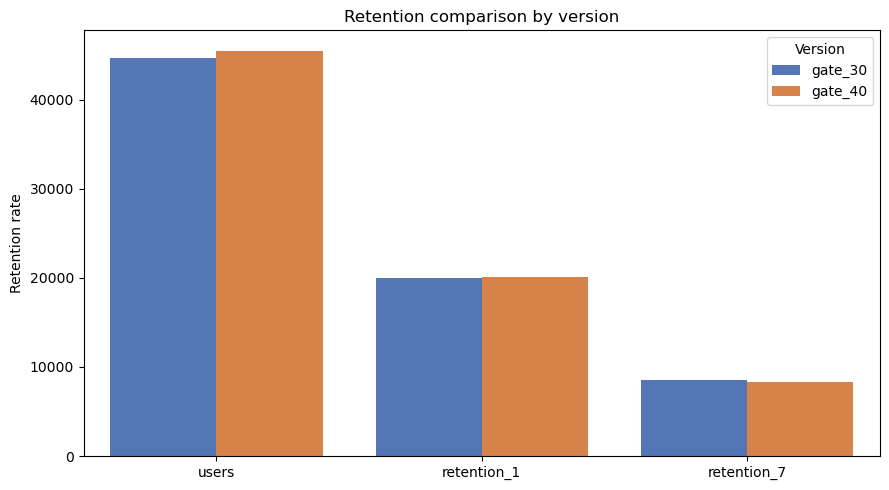

In [ ]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=df_plot,
    x="Metric",
    y="value",
    hue="version",
    palette=["#4472C4", "#ED7D31"]
)

plt.title("Retention comparison by version")
plt.ylabel("Retention rate")
plt.xlabel("")
plt.legend(title="Version")

plt.tight_layout()
plt.show()

> Final remarks

The experiment has another issue: with a gate at level 30-40, **many players did not even reach the gate** (not meaningful for a comparison)
* the real data should include only players with games > 40 (not sure of the amount of games to meet the gate)
* the likelihood of reaching the gate is very low in the retention_1 metric, but higher in retention_7 

Much more information and data would be necessary